Loading and preprocessing Fashion-MNIST...

Starting Adversarial Training Pipeline...
Epoch 1/3 completed.
Epoch 2/3 completed.
Epoch 3/3 completed.

Performing Style Mixing Execution...


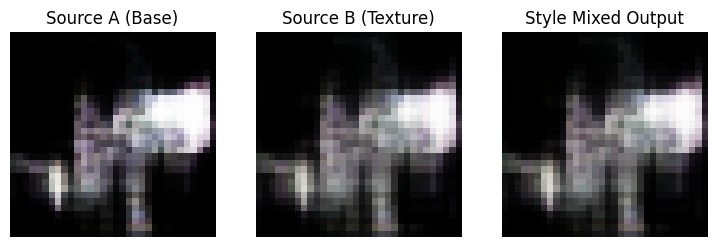


Performing Latent Space Linear Interpolation...


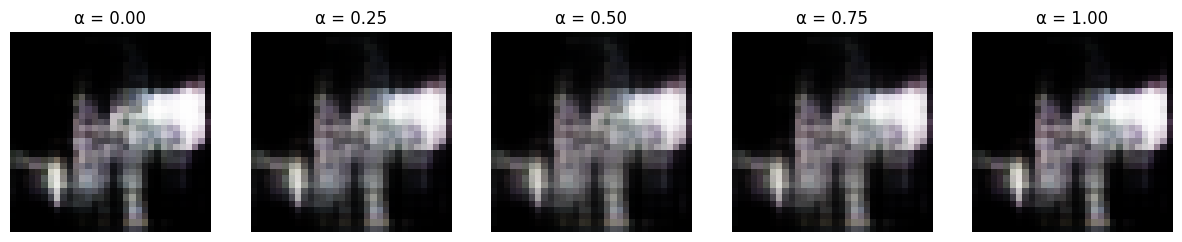

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models

# Prevent TensorFlow from consuming all GPU memory at once
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# 1. Dataset Preparation (Fashion-MNIST)
print("Loading and preprocessing Fashion-MNIST...")
(x_train, _), (_, _) = tf.keras.datasets.fashion_mnist.load_data()

# Resize to 32x32 and convert to 3 channels (RGB) to simulate color image pipeline
x_train = np.expand_dims(x_train, axis=-1)
x_train = tf.image.resize(x_train, [32, 32])
x_train = tf.image.grayscale_to_rgb(x_train)

# Normalize to [-1, 1] range as per GAN standards
x_train = (x_train - 127.5) / 127.5
x_train = tf.cast(x_train, tf.float32)

BATCH_SIZE = 64
LATENT_DIM = 128

train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(buffer_size=1024)
    .batch(BATCH_SIZE, drop_remainder=True)
)


# 2. Mapping Network (f: z -> w)
def build_mapping_network(latent_dim=128):
    # 8 fully connected layers to disentangle the latent space
    inputs = layers.Input(shape=(latent_dim,))
    x = inputs
    for _ in range(8):
        x = layers.Dense(latent_dim)(x)
        x = layers.LeakyReLU(negative_slope=0.2)(x)
    return models.Model(inputs, x, name="Mapping_Network")


# 3. Adaptive Instance Normalisation (AdaIN) Layer
class AdaIN(layers.Layer):

    def __init__(self, channels):
        super(AdaIN, self).__init__()
        # Dense layers to extract scale (gamma) and shift (beta) coefficients from style w
        self.gamma_dense = layers.Dense(channels)
        self.beta_dense = layers.Dense(channels)

    def call(self, inputs):
        x, w = inputs

        # Calculate spatial mean and variance across H and W dimensions
        mean, variance = tf.nn.moments(x, axes=[1, 2], keepdims=True)
        epsilon = 1e-5
        normalized_x = (x - mean) / tf.math.sqrt(variance + epsilon)

        # Generate affine transformation coefficients from style vector w
        gamma = self.gamma_dense(w)[:, tf.newaxis, tf.newaxis, :]
        beta = self.beta_dense(w)[:, tf.newaxis, tf.newaxis, :]

        return gamma * normalized_x + beta


# Core Synthesis Building Block
def adain_conv_block(x, w, channels, kernel_size=3):
    x = layers.Conv2D(
        channels, kernel_size, padding="same", kernel_initializer="he_normal"
    )(x)
    x = AdaIN(channels)([x, w])
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    return x


# 3. Build Synthesis Network (Generator Model)
class StyleGenerator(models.Model):

    def __init__(self, latent_dim=128):
        super(StyleGenerator, self).__init__()
        self.mapping = build_mapping_network(latent_dim)

        # Learned constant tensor initiation (4x4x128)
        self.const = tf.Variable(
            tf.random.normal([1, 4, 4, 128]), trainable=True, name="const_tensor"
        )

        # Resolution blocks
        self.block1_adain = AdaIN(128)
        self.block1_conv = layers.Conv2D(
            128, 3, padding="same", kernel_initializer="he_normal"
        )
        self.block1_adain2 = AdaIN(128)

        # 8x8 resolution
        self.up1 = layers.UpSampling2D()
        self.conv1_1 = layers.Conv2D(
            64, 3, padding="same", kernel_initializer="he_normal"
        )
        self.adain1_1 = AdaIN(64)

        # 16x16 resolution
        self.up2 = layers.UpSampling2D()
        self.conv2_1 = layers.Conv2D(
            32, 3, padding="same", kernel_initializer="he_normal"
        )
        self.adain2_1 = AdaIN(32)

        # 32x32 resolution
        self.up3 = layers.UpSampling2D()
        self.conv3_1 = layers.Conv2D(
            16, 3, padding="same", kernel_initializer="he_normal"
        )
        self.adain3_1 = AdaIN(16)

        # Final output layer to map to image channels (RGB)
        self.to_rgb = layers.Conv2D(3, 1, activation="tanh", padding="same")

    def call(self, inputs, training=None, style_mixing_step=None):
        """
        inputs: if style mixing, tuple of (z1, z2); else single z tensor
        style_mixing_step: layer resolution block index to switch styles
        """
        if isinstance(inputs, tuple) and style_mixing_step is not None:
            z1, z2 = inputs
            w1 = self.mapping(z1)
            w2 = self.mapping(z2)
        else:
            w1 = self.mapping(inputs)
            w2 = w1

        # Tile constant tensor dynamically for batch size
        batch_size = tf.shape(w1)[0]
        x = tf.tile(self.const, [batch_size, 1, 1, 1])

        # 4x4 resolution execution
        x = self.block1_adain([x, w1])
        x = self.block1_conv(x)
        x = self.block1_adain2([x, w1])

        # 8x8 resolution execution
        w_current = w2 if (style_mixing_step is not None and style_mixing_step <= 1) else w1
        x = self.up1(x)
        x = self.conv1_1(x)
        x = self.adain1_1([x, w_current])

        # 16x16 resolution execution
        w_current = w2 if (style_mixing_step is not None and style_mixing_step <= 2) else w1
        x = self.up2(x)
        x = self.conv2_1(x)
        x = self.adain2_1([x, w_current])

        # 32x32 resolution execution
        w_current = w2 if (style_mixing_step is not None and style_mixing_step <= 3) else w1
        x = self.up3(x)
        x = self.conv3_1(x)
        x = self.adain3_1([x, w_current])

        return self.to_rgb(x)


# 4. Standard Convolutional Discriminator
def build_discriminator():
    model = models.Sequential(
        [
            layers.Input(shape=(32, 32, 3)),
            layers.Conv2D(32, 3, strides=2, padding="same"),
            layers.LeakyReLU(negative_slope=0.2),
            layers.Dropout(0.3),
            layers.Conv2D(64, 3, strides=2, padding="same"),
            layers.LeakyReLU(negative_slope=0.2),
            layers.Dropout(0.3),
            layers.Flatten(),
            layers.Dense(1),
        ],
        name="Discriminator",
    )
    return model


# Initialize Subnetworks
generator = StyleGenerator(LATENT_DIM)
discriminator = build_discriminator()

# Define Loss and Optimizers
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)


def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss


def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)


generator_optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.0, beta_2=0.99)
discriminator_optimizer = tf.keras.optimizers.Adam(4e-4, beta_1=0.0, beta_2=0.99)


# 5. Non-Saturating Adversarial Training Step
@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, LATENT_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )
    gradients_of_discriminator = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(gradients_of_generator, generator.trainable_variables)
    )
    discriminator_optimizer.apply_gradients(
        zip(gradients_of_discriminator, discriminator.trainable_variables)
    )


# Short Training loop (Demonstration Epochs)
EPOCHS = 3
print("\nStarting Adversarial Training Pipeline...")
for epoch in range(EPOCHS):
    for image_batch in train_dataset:
        train_step(image_batch)
    print(f"Epoch {epoch+1}/{EPOCHS} completed.")


# Helper normalization conversion to display images properly
def convert_to_display(img):
    img = (img + 1.0) / 2.0
    return np.clip(img, 0.0, 1.0)


# ==========================================
# 6. Style Mixing Demonstration
# ==========================================
print("\nPerforming Style Mixing Execution...")
z_source_a = tf.random.normal([1, LATENT_DIM])
z_source_b = tf.random.normal([1, LATENT_DIM])

# Output under single profiles
img_a = generator(z_source_a, training=False)[0]
img_b = generator(z_source_b, training=False)[0]

# Generate cross mixed style (switch styles at layer index 2)
mixed_img = generator((z_source_a, z_source_b), training=False, style_mixing_step=2)[
    0
]

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(convert_to_display(img_a))
axes[0].set_title("Source A (Base)")
axes[0].axis("off")

axes[1].imshow(convert_to_display(img_b))
axes[1].set_title("Source B (Texture)")
axes[1].axis("off")

axes[2].imshow(convert_to_display(mixed_img))
axes[2].set_title("Style Mixed Output")
axes[2].axis("off")
plt.show()


# ==========================================
# 7. Latent Linear Interpolation (z1 -> z2)
# ==========================================
print("\nPerforming Latent Space Linear Interpolation...")
z1 = tf.random.normal([1, LATENT_DIM])
z2 = tf.random.normal([1, LATENT_DIM])

steps = 5
interpolation_weights = np.linspace(0, 1, steps)
interpolated_images = []

for alpha in interpolation_weights:
    # Linear interpolation combination formulation between vectors
    z_interp = (1 - alpha) * z1 + alpha * z2
    img_interp = generator(z_interp, training=False)[0]
    interpolated_images.append(convert_to_display(img_interp))

fig, axes = plt.subplots(1, steps, figsize=(15, 3))
for i, img in enumerate(interpolated_images):
    axes[i].imshow(img)
    axes[i].set_title(f"\u03b1 = {interpolation_weights[i]:.2f}")
    axes[i].axis("off")
plt.show()